# Cvičení 4: Tok v síti, třídění zásilek a proložení přímky

Řešení.

Spouštějte buňky shora dolů. Nejprve spusťte instalaci PuLP 3.3.2 v sekci 0 a postupujte podle případného pokynu k restartu jádra. Modelová data vznikají přímo v notebooku. V sekcích 4 a 6 doplňte vlastní výpočet.

## 0. Příprava prostředí — spusťte jako první
Tato buňka nainstaluje **PuLP 3.3.2** do prostředí aktuálního notebooku, pokud
správná verze chybí. Stačí ji spustit; příkazy není potřeba upravovat.

Pokud už máte v paměti PuLP 4, buňka po instalaci výpočet zastaví a vyzve
k **restartu relace/jádra**. V Colabu otevřete nabídku **Runtime (Běhové prostředí)**
a zvolte restart relace; v Jupyteru **Kernel → Restart Kernel**. Potom spusťte
notebook znovu shora. Samotné opakování `import pulp` starou verzi z paměti neodstraní.
Po hlášení „Připraveno“ můžete pokračovat. Instalace vyžaduje připojení k internetu.

In [1]:
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

REQUIRED_PULP = "3.3.2"
try:
    installed_pulp = version("pulp")
except PackageNotFoundError:
    installed_pulp = None

if installed_pulp != REQUIRED_PULP:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "--disable-pip-version-check", "--no-cache-dir", "pulp==3.3.2"
    ])
if version("pulp") != REQUIRED_PULP:
    raise RuntimeError("PuLP 3.3.2 se nenainstalovalo. Zkontrolujte výpis instalace výše.")

loaded_pulp = sys.modules.get("pulp")
if loaded_pulp is not None and getattr(loaded_pulp, "__version__", None) != REQUIRED_PULP:
    raise RuntimeError(
        "PuLP 3.3.2 je nainstalované, ale v paměti zůstává jiná verze. "
        "V Colabu zvolte Runtime > Restart session (případně Restart runtime). "
        "V Jupyteru zvolte Kernel > Restart Kernel. Potom spusťte všechny buňky shora."
    )
print("Připraveno: PuLP 3.3.2 je nainstalované. Pokračujte dalšími buňkami.")

Připraveno: PuLP 3.3.2 je nainstalované. Pokračujte dalšími buňkami.


## Co si dnes vyzkoušíme
Jedna zásilková společnost má tři otázky. U každé si před výpočtem řekněte, **co je zadáno a co má model najít**.

1. **Přeprava mezi depy (části 1–5).** Známe kapacity spojů. Hledáme, kolik zásilek po každém spoji poslat. Začneme dvěma trasami, na kterých lze výsledek ověřit ručně. Stejný model pak použijeme na síť se 146 uzly a 864 spoji a vyzkoušíme výpadek třídicího centra.
2. **Třídění uvnitř depa (část 6).** Známe rozměry a hmotnosti zásilek i způsob jejich zpracování. Hledáme přímku, která oddělí dvě skupiny zásilek.
3. **Příkon serveru v depu (část 7).** Známe dvojice měření vytížení a příkonu. Opět hledáme přímku, tentokrát pro odhad příkonu ve wattech. O její kvalitě rozhoduje velikost odchylek od měření.

Každá otázka má vlastní data. V prvním modelu je výsledkem přepravní plán, ve druhém pravidlo pro třídění a ve třetím vztah pro odhad příkonu.

In [2]:
import pulp
import numpy as np
import matplotlib.pyplot as plt

if pulp.__version__ != "3.3.2":
    raise RuntimeError("Spusťte sekci 0 a postupujte podle pokynu k restartu.")
solver = pulp.PULP_CBC_CMD(msg=False)
tol = 1e-5

## 1. Kolik zásilek projde sítí dep?
Z výchozího depa S posíláme zásilky do cílového depa T. Šipky udávají povolené směry, čísla kapacity v zásilkách za hodinu. Uvažujeme ustálený provoz bez hromadění zásilek v překladištích. Proměnné proto vyjadřují průměrné hodinové toky. Jaký tok dokážete rozdělit mezi horní a dolní větev?

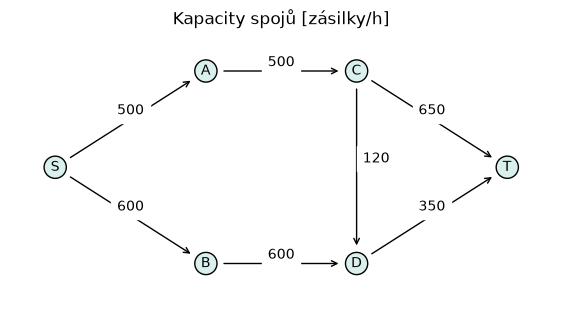

In [3]:
capacity = {("S", "A"): 500, ("A", "C"): 500, ("C", "T"): 650,
            ("S", "B"): 600, ("B", "D"): 600, ("D", "T"): 350,
            ("C", "D"): 120}
pos = {"S": (0, 0), "A": (1, 1), "B": (1, -1), "C": (2, 1),
       "D": (2, -1), "T": (3, 0)}
fig, ax = plt.subplots(figsize=(7, 3.5))
for (u, v), cap in capacity.items():
    x, y = pos[u]
    xx, yy = pos[v]
    ax.annotate("", pos[v], pos[u], arrowprops=dict(arrowstyle="->", shrinkA=13, shrinkB=13))
    ax.text((x+xx)/2 + (0.13 if x == xx else 0), (y+yy)/2+0.05, str(cap),
            ha="center", backgroundcolor="white")
for node, (x, y) in pos.items():
    ax.text(x, y, node, ha="center", va="center",
            bbox=dict(boxstyle="circle", facecolor="#daf0ed"))
ax.set(xlim=(-0.3, 3.3), ylim=(-1.4, 1.4), title="Kapacity spojů [zásilky/h]")
ax.axis("off")
plt.show()

## 2. Od jednoho překladiště k celé síti
Pro spoj $(u,v)$ zavedeme proměnnou $0\leq x_{uv}\leq c_{uv}$. V překladišti C musí platit $x_{AC}=x_{CT}+x_{CD}$. Jak vypadá stejná rovnice pro D?

V PuLP projdeme všechna překladiště a pro každé sečteme přítok a odtok. Účelovou funkcí je celkový přítok do T, který maximalizujeme. Do S žádný spoj nevstupuje a z T žádný nevychází. Parametr `omit` použijeme později při hledání chyby.

### Matematický model maximálního toku
Množina $V$ obsahuje všechna depa včetně zdroje $S$ a cílového depa $T$. Množina $E$ obsahuje směrované spoje. Kapacita $c_{uv}$ je známá, zatímco tok $x_{uv}$ určuje model. Obě veličiny měříme v zásilkách za hodinu.

$$
\begin{aligned}
\max_x\quad & \sum_{(u,T)\in E} x_{uT} \\
\text{za podmínek}\quad &
\sum_{(u,v)\in E}x_{uv}=\sum_{(v,w)\in E}x_{vw}
&& v\in V\setminus\{S,T\},\\
&0\le x_{uv}\le c_{uv} && (u,v)\in E.
\end{aligned}
$$

První řádek počítá všechny zásilky doručené do T. Prostřední řádek pro každé překladiště porovnává spoje, které v něm končí, se spoji, které v něm začínají. V kódu mu odpovídá rovnice `incoming == outgoing`. Poslední řádek zadáme přímo při vytvoření proměnné pomocí `lowBound` a `upBound`.

In [4]:
def route(capacities, omit=None):
    model = pulp.LpProblem("parcel_flow", pulp.LpMaximize)
    flow = {(u, v): pulp.LpVariable(f"x_{u}_{v}", lowBound=0, upBound=limit)
            for (u, v), limit in capacities.items()}
    model += pulp.lpSum(flow[u, v] for u, v in flow if v == "T")
    nodes = {node for edge in flow for node in edge}
    for node in sorted(nodes - {"S", "T", omit}):
        incoming = pulp.lpSum(flow[u, v] for u, v in flow if v == node)
        outgoing = pulp.lpSum(flow[u, v] for u, v in flow if u == node)
        model += incoming == outgoing, f"balance_{node}"
    status = model.solve(solver)
    print(pulp.LpStatus[status])
    if status != pulp.LpStatusOptimal:
        raise RuntimeError(pulp.LpStatus[status])
    return {edge: x.value() for edge, x in flow.items()}

plan = route(capacity)
for edge, amount in plan.items():
    print(" → ".join(edge), amount, "/", capacity[edge])

Optimal
S → A 500.0 / 500
A → C 500.0 / 500
C → T 500.0 / 650
S → B 350.0 / 600
B → D 350.0 / 600
D → T 350.0 / 350
C → D 0.0 / 120


## 3. Kontrola výsledku a hledání chyby
Kontrolu provedeme z hodnot toků na spojích. Pro každé depo vypočteme odtok minus přítok. V překladištích čekáme nulu. Ve zdroji čekáme stejnou hodnotu jako v cíli s opačným znaménkem. Zkontrolujeme také meze všech toků.

### Co změří kontrola bilance?
Ze získaného plánu spočteme pro každý uzel rozdíl mezi odtokem a přítokem,

$$
d_v=\sum_{(v,w)\in E}x_{vw}-\sum_{(u,v)\in E}x_{uv}.
$$

V překladišti má být $d_v=0$. Pokud $d_v>0$, odjíždí odtud více zásilek, než kolik jich přijelo. Pro hodnotu toku $F$ dále platí $d_S=F$ a $d_T=-F$. Funkce `balances` provede tento přepočet ze spojů i tehdy, když některá rovnice v modelu chybí.

In [5]:
def balances(plan):
    net = {}
    for (u, v), amount in plan.items():
        net[u] = net.get(u, 0) + amount
        net[v] = net.get(v, 0) - amount
    return net

def check_plan(plan, capacities):
    net = balances(plan)
    assert all(-tol <= plan[e] <= limit + tol for e, limit in capacities.items())
    assert all(abs(value) <= tol for node, value in net.items() if node not in ("S", "T"))
    assert abs(net["S"] + net["T"]) <= tol
    return -net["T"]

print(balances(plan))
print("Tok [zásilky/h]:", check_plan(plan, capacity))

{'S': 850.0, 'A': 0.0, 'C': 0.0, 'T': -850.0, 'B': 0.0, 'D': 0.0}
Tok [zásilky/h]: 850.0


In [6]:
suspect = route(capacity, omit="C")
print(balances(suspect))

Optimal
{'S': 350.0, 'A': 0.0, 'C': 650.0, 'T': -1000.0, 'B': 0.0, 'D': 0.0}


O kolik se liší přítok do T od odtoku ze S? Najděte překladiště, kde rozdíl vznikl, a určete chybějící rovnici. Stav `Optimal` se vztahuje k omezením, která jsme řešiči předali.

V D musí platit $x_{BD}+x_{CD}=x_{DT}$. V uvedeném chybném výpočtu opouští S jen 350 zásilek/h a do T přichází 1 000. Rozdíl 650 zásilek/h vzniká v C. Chybný model připouští více optimálních řešení, takže přebytek v C může vyjít i jinak. Obnovíme rovnici $x_{AC}=x_{CT}+x_{CD}$ voláním `route(capacity)`. Správná hodnota je 850 zásilek/h. Do horní větve vstoupí nejvýše 500 a z dolní větve dorazí do T nejvýše 350. Zobrazený přípustný plán této meze dosahuje.

## 4. Který spoj posílit? Doplňte dvě varianty
Máme prostředky na zvýšení kapacity **jednoho** spoje o 100 zásilek/h. Uvažujte zvlášť A → C a D → T. Oba jsou v původním řešení vytížené. Před spuštěním odhadněte, která změna umožní doručit více zásilek. Pro každou variantu vytvořte kopii původních kapacit, změňte jednu položku, zavolejte `route` a výsledek ověřte pomocí `check_plan`.

In [7]:
for edge in [("A", "C"), ("D", "T")]:
    changed = capacity.copy()
    changed[edge] += 100
    result = check_plan(route(changed), changed)
    print(edge, result, "Δ =", result - check_plan(plan, capacity))

Optimal
('A', 'C') 850.0 Δ = 0.0
Optimal
('D', 'T') 950.0 Δ = 100.0


Posílení A → C nepomohlo, protože do A stále přitéká nejvýše 500 zásilek/h. Posílení D → T zvýšilo tok z 850 na 950 zásilek/h. Být plně vytížený tedy samo o sobě nestačí k rozhodnutí o investici.

## 5. Noční přeprava v síti se 146 uzly
V modelové síti zásilky postupně procházejí svozovým depem, třídicím centrem a rozvozovým depem. V každé skupině je 48 provozoven. S a T jsou souhrnné uzly pro vstup a výstup celé sítě. Každá provozovna v prvních dvou skupinách má osm navazujících spojů. Celkem dostaneme 864 proměnných toku a 144 bilančních rovnic.

Dispečer potřebuje vědět, kolik zásilek lze přepravit za hodinu a jak se výsledek změní, když jedno vytížené třídicí centrum vypadne. Pracujeme se syntetickými daty a průměrnými hodinovými kapacitami.

In [8]:
rng = np.random.default_rng(41)
width = 48
collection, hubs, delivery = [
    [f"{prefix}{j:02d}" for j in range(width)] for prefix in ["A", "B", "C"]
]
large = {("S", node): int(rng.integers(850, 1350)) for node in collection}
for left, right in [(collection, hubs), (hubs, delivery)]:
    for j, u in enumerate(left):
        for offset in range(8):
            large[u, right[(j + offset) % width]] = int(rng.integers(90, 215))
for node in delivery:
    large[node, "T"] = int(rng.integers(850, 1350))

large_plan = route(large)
baseline = check_plan(large_plan, large)
print("Spoje:", len(large), "| Tok [zásilky/h]:", baseline)
print("Největší odchylka bilance:", max(abs(n) for v, n in balances(large_plan).items()
                                        if v not in ("S", "T")))

Optimal
Spoje: 864 | Tok [zásilky/h]: 52651.0
Největší odchylka bilance: 0.0


### Výpadek třídicího centra
Z původního plánu vybereme centrum $h$ s největším průtokem. Pro každý spoj vedoucí do $h$ nebo z $h$ nastavíme kapacitu na nulu. Ostatní kapacity zachováme a model znovu vyřešíme. Označíme-li maximální toky před výpadkem a po něm $F$ a $F_h$, hodinová ztráta je

$$\Delta F=F-F_h.$$

Odhadněte předem: ztratíme celý původní průtok centra, nebo půjde část zásilek přesměrovat?

In [9]:
hub_load = {h: sum(x for (u, v), x in large_plan.items() if v == h) for h in hubs}
closed = max(hubs, key=hub_load.get)
after = {edge: 0 if closed in edge else limit for edge, limit in large.items()}
revised = check_plan(route(after), after)
print("Centrum:", closed, "| Původní průtok centra:", hub_load[closed])
print("Tok po výpadku:", revised, "| Ztráta [zásilky/h]:", baseline - revised)

Optimal
Centrum: B40 | Původní průtok centra: 1319.0
Tok po výpadku: 51779.0 | Ztráta [zásilky/h]: 872.0


V zobrazeném plánu prochází centrem B40 celkem 1 319 zásilek za hodinu. Po jeho uzavření se celkový tok sníží o 872 zásilek za hodinu. Přesměrováním tedy síť přepraví o 447 zásilek za hodinu více, než kdyby přišla o celý původní průtok centra.

## 6. Které zásilky prošly automatickou linkou?
Přepravní plán nám řekl, kolik zásilek do depa přijede. Teď se podíváme na jednu zásilku po příjezdu. Obsluha má záznamy o tom, které zásilky poslala na pás a které zpracovala ručně. Lze její rozhodnutí popsat jediným pravidlem podle délky a hmotnosti?

Každý z následujících 150 modelových záznamů obsahuje délku nejdelší strany v cm, hmotnost v kg a způsob zpracování. Nejdřív si prohlédněte body. Dokážete mezi obě skupiny zakreslit přímku? Barvy i tvary symbolů označují způsob zpracování.

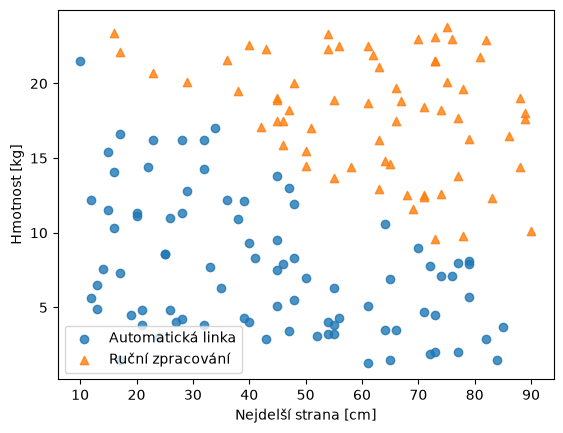

In [10]:
rng = np.random.default_rng(42)
length = rng.integers(10, 91, 150)
mass = rng.uniform(1, 24, 150).round(1)
# První zásilka je krabice. V další variantě k ní přidáme tubus.
length[0], mass[0] = 40, 4
manual = mass + 0.2 * length > 24

def parcel_plot():
    for mask, marker, label in [(~manual, "o", "Automatická linka"),
                                (manual, "^", "Ruční zpracování")]:
        plt.scatter(length[mask], mass[mask], marker=marker, label=label, alpha=0.8)
    plt.xlabel("Nejdelší strana [cm]")
    plt.ylabel("Hmotnost [kg]")
    plt.legend()

parcel_plot()
plt.show()

Hledáme koeficienty $a,b,c$ přímky $a\ell+bm+c=0$. Pro ruční zpracování požadujeme $a\ell+bm+c\geq1$, pro automatickou linku $a\ell+bm+c\leq-1$. Jednička určuje měřítko koeficientů. Pokud přímka konečný soubor bodů ostře odděluje, lze její koeficienty vynásobit kladnou konstantou tak, aby obě nerovnosti platily. Hledáme libovolné přípustné řešení, proto zvolíme konstantní účelovou funkci.

### LP pro oddělení dvou skupin
Označme $R$ záznamy o ručně tříděných zásilkách a $A$ záznamy o automaticky tříděných zásilkách. Délka $\ell_i$ a hmotnost $m_i$ jsou vstupní data. Volíme tři reálné koeficienty.

$$
\begin{aligned}
\min_{a,b,c\in\mathbb R}\quad &0\\
a\ell_i+bm_i+c &\ge 1 && i\in R,\\
a\ell_i+bm_i+c &\le -1 && i\in A.
\end{aligned}
$$

Každý záznam přidá právě jednu nerovnost. Obě skupiny tak musí ležet na opačných stranách přímky. V kódu podle příznaku `by_hand` vybíráme mezi dvěma směry nerovnosti. Řádek `model += 0` vyjadřuje, že nám stačí najít libovolné přípustné řešení.

Optimal


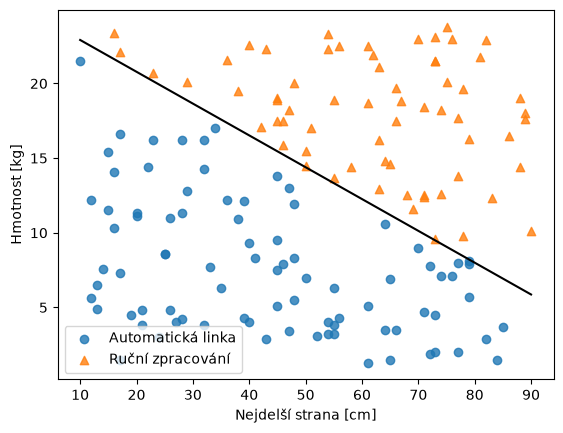

In [11]:
def separator(records):
    model = pulp.LpProblem("sorting")
    a, b, c = [pulp.LpVariable(name) for name in ("a", "b", "c")]
    model += 0
    for side, weight, by_hand in records:
        score = a * int(side) + b * float(weight) + c
        model += (score >= 1) if by_hand else (score <= -1)
    status = model.solve(solver)
    print(pulp.LpStatus[status])
    if status == pulp.LpStatusOptimal:
        return a.value(), b.value(), c.value()
    return None

records = list(zip(length, mass, manual))
a, b, c = separator(records)
scores = a * length + b * mass + c
assert min(scores[manual]) >= 1 - tol and max(scores[~manual]) <= -1 + tol
parcel_plot()
xs = np.array([length.min(), length.max()])
if abs(b) > tol:
    plt.plot(xs, -(a * xs + c) / b, color="black")
else:
    plt.axvline(-c/a, color="black")
plt.show()

**Doplňte pokus s tubusem.** Krabice o délce 40 cm a hmotnosti 4 kg prošla automatickou linkou. Tubus o stejné délce a hmotnosti musela obsluha zpracovat ručně, protože se kutálí. Přidejte jej k původním záznamům a před spuštěním odhadněte stav řešiče. Kterou další vlastnost zásilky by mělo depo evidovat?

In [12]:
separator(records + [(40, 4, True)])

Infeasible


Oba předměty mají v modelu stejné skóre. Nemůže být současně nejvýše −1 a nejméně 1. Úloha je nepřípustná. Depo by mohlo zaznamenávat také tvar zásilky.

## 7. Jak souvisí příkon serveru s jeho vytížením?
V předchozím grafu měla každá zásilka štítek a rozhodovalo, na které straně přímky leží. Server v depu nám dává jiný druh dat. Jeden bod teď znamená jedno měření a svislá souřadnice udává naměřený příkon. Přímku budeme číst jako předpověď: při známém vytížení z ní odečteme odhad příkonu a porovnáme ho s měřením.

Při zátěžové zkoušce sledujeme vytížení $u$ v procentech a příkon $P$ ve wattech. Chceme z měření odhadnout přímku $P(u)=au+b$. Pro 300 modelových měření porovnáme dvě kritéria. První minimalizuje součet absolutních odchylek, druhé největší absolutní odchylku. Co udělá s oběma přímkami jediné neobvykle vysoké měření?

Pro reziduum $r_i=au_i+b-P_i$ zavedeme $e_i\geq r_i$ a $e_i\geq-r_i$. Při minimalizaci součtu $e_i$ dostaneme součet absolutních odchylek. Pro druhé kritérium použijeme pro všechna měření jednu společnou mez $t$ a minimalizujeme ji.

### Dvě účelové funkce pro stejná měření
Index $i=1,\ldots,n$ označuje měření. Vytížení $u_i$ a naměřený příkon $P_i$ známe. Hledáme směrnici $a$ a absolutní člen $b$, oba bez omezení znaménka. Reziduum $r_i=au_i+b-P_i$ měříme ve wattech.

**Součet absolutních odchylek.** Každému měření přiřadíme vlastní nezápornou mez $e_i$.

$$
\min_{a,b,\,e_i\ge0}\ \sum_{i=1}^n e_i
\qquad\text{za podmínek}\quad -e_i\le r_i\le e_i\quad(i=1,\ldots,n).
$$

Menší hodnota $e_i$ zlepší účelovou funkci, takže v optimu $e_i=|r_i|$. V kódu jde o větev `criterion == "sum"`.

**Největší absolutní odchylka.** Pro všechna měření použijeme jedinou společnou nezápornou mez $t$.

$$
\min_{a,b,\,t\ge0}\ t
\qquad\text{za podmínek}\quad -t\le r_i\le t\quad(i=1,\ldots,n).
$$

Nejmenší přípustná mez je pro danou přímku rovna největší absolutní odchylce. V druhé větvi kódu proto vkládáme stejnou proměnnou `t` do obou nerovností pro každé měření.

In [13]:
rng = np.random.default_rng(43)
load = np.linspace(5, 100, 300)
power = 85 + 1.65 * load + rng.normal(0, 3, len(load))
changed_power = power.copy()
changed_power[150] += 90

def fit(readings, criterion):
    model = pulp.LpProblem("server_power", pulp.LpMinimize)
    a, b = pulp.LpVariable("slope"), pulp.LpVariable("intercept")
    if criterion == "sum":
        bounds = [pulp.LpVariable(f"e_{i}", lowBound=0) for i in range(len(load))]
        model += pulp.lpSum(bounds)
    else:
        t = pulp.LpVariable("t", lowBound=0)
        bounds = [t] * len(load)
        model += t
    for u, p, bound in zip(load, readings, bounds):
        residual = a * float(u) + b - float(p)
        model += bound >= residual
        model += bound >= -residual
    status = model.solve(solver)
    if status != pulp.LpStatusOptimal:
        raise RuntimeError(pulp.LpStatus[status])
    predicted = a.value() * load + b.value()
    errors = abs(predicted - readings)
    checked = errors.sum() if criterion == "sum" else errors.max()
    assert np.isclose(checked, pulp.value(model.objective), rtol=1e-5)
    return predicted, errors.mean(), errors.max()

Původní měření | průměrná / největší absolutní odchylka [W]
Součet 2.4 / 8.69
Maximum 2.53 / 8.13


Jedno zvýšené měření | průměrná / největší absolutní odchylka [W]
Součet 2.68 / 86.2
Maximum 39.42 / 46.94


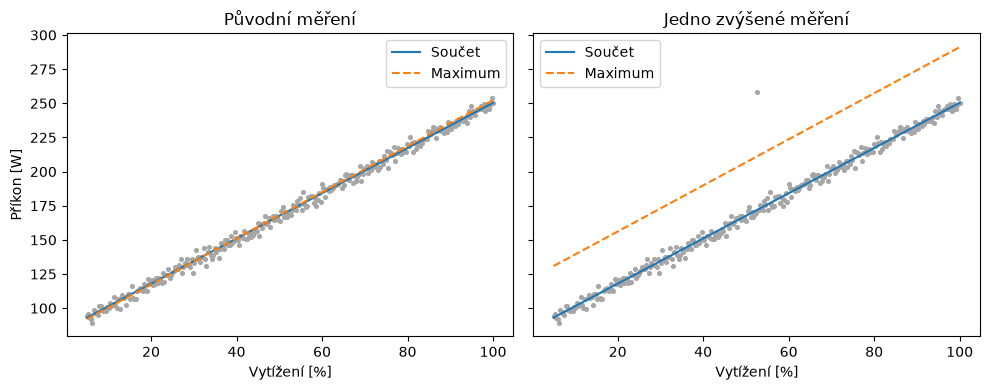

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, readings, title in zip(axes, [power, changed_power],
                               ["Původní měření", "Jedno zvýšené měření"]):
    ax.scatter(load, readings, s=7, color="0.65")
    print(title, "| průměrná / největší absolutní odchylka [W]")
    for criterion, label, style in [("sum", "Součet", "-"), ("max", "Maximum", "--")]:
        predicted, mean_error, max_error = fit(readings, criterion)
        ax.plot(load, predicted, style, label=label)
        print(label, round(mean_error, 2), "/", round(max_error, 2))
    ax.set(title=title, xlabel="Vytížení [%]")
    ax.legend()
axes[0].set_ylabel("Příkon [W]")
fig.tight_layout()
plt.show()

Porovnejte oba grafy. Které kritérium byste zvolili, pokud se zodpovídáte za největší chybu na naměřených datech? A které, pokud má každá další odchylka o jeden watt stejnou váhu? Do projektu si můžete převzít i způsob kontroly: dosažené odchylky přepočítejte přímo z měření a výsledné přímky.

Po zvýšení jediného měření se přímka minimalizující největší odchylku posune směrem k tomuto bodu. Zmírní tak největší chybu za cenu větších odchylek u většiny ostatních měření. Přímka minimalizující součet se v tomto pokusu změní jen málo. Po změně měření u ní vychází průměrná absolutní odchylka 2,68 W a největší 86,20 W. U druhé přímky je to 39,42 W a 46,94 W.

Náměty úloh vycházejí z oddílů 2.2, 2.4 a 2.5 textu [Jiří Matoušek, Lineární programování](https://iti.mff.cuni.cz/series/2006/311.pdf). Scénáře a data byly vytvořeny pro toto cvičení.